# 6. Spectra, the Beer–Lambert law and preprocessing

A near-infrared spectrum of a process stream depends on the composition, and also on the path length, on scattering and on the baseline of the instrument. This lecture states the Beer–Lambert law for a mixture and two standard corrections: the standard normal variate (SNV), which removes a multiplicative factor and an offset from each spectrum, and the first derivative, which removes a constant baseline. Their effect on a calibration is measured on synthetic spectra.

## Learning objectives

1. State the Beer–Lambert law for a mixture, with a path length and a baseline for each spectrum.
2. Show, and check numerically, that the standard normal variate (`dim_reduction.snv_preprocess`) removes a positive scale factor and a constant offset.
3. Use the first derivative of a spectrum (`dim_reduction.spectral_first_derivative`) to remove a constant baseline, and see what it does to the noise.
4. Compare a PLS calibration before and after each preprocessing step.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
By the **multicomponent Beer–Lambert law**, the absorbance spectrum $A_i(\lambda_j)$ ($\mathrm{AU}$, dimensionless absorbance units) of sample $i$ across $d$ wavelengths $\lambda_1 < \dots < \lambda_d$ ($\mathrm{nm}$) is a linear superposition of $S$ species molar concentrations $c_{i,s}$ ($\mathrm{mol/L}$) weighted by molar absorptivities $\varepsilon_s(\lambda_j)$ ($\mathrm{L/(mol\cdot cm)}$), corrupted by effective optical path length $b_i$ ($\mathrm{cm}$) and baseline drift $\alpha_i + \beta_i\lambda_j$:
$$A_i(\lambda_j) = b_i \sum_{s=1}^S c_{i,s}\,\varepsilon_s(\lambda_j) + \alpha_i + \beta_i \lambda_j + \varepsilon_{i,j} \tag{1.1}$$
1. **Standard normal variate (SNV, Barnes et al. 1989):** Centers each spectrum across wavelengths and divides by its row standard deviation:
   $$A_{i,j}^{\mathrm{SNV}} = \frac{A_{i,j} - \bar{A}_i}{s_i}, \qquad \bar{A}_i = \frac{1}{d}\sum_{k=1}^d A_{i,k}, \quad s_i = \sqrt{\frac{1}{d}\sum_{k=1}^d (A_{i,k} - \bar{A}_i)^2} \tag{1.2}$$
   For any pure path-length scaling $b_i > 0$ and offset $\alpha_i$ ($\beta_i = 0$), $A_{i,j} = b_i A_{0,j} + \alpha_i \implies A_{i,j}^{\mathrm{SNV}} \equiv A_{0,j}^{\mathrm{SNV}}$.
2. **First derivative of the spectrum ($dA/d\lambda$):** Differentiating with respect to wavelength $\lambda$ annihilates $\alpha_i$ and turns linear tilts $\beta_i\lambda_j$ into a constant offset $\beta_i$ that a subsequent SNV pass removes completely:
   $$\frac{\partial A_i(\lambda_j)}{\partial \lambda} = b_i \sum_{s=1}^S c_{i,s}\,\varepsilon_s'(\lambda_j) + \beta_i \tag{1.3}$$

In [2]:
heading("Demonstration 1: Exact Path-Length & Offset Invariance of Standard Normal Variate (SNV)")
wl = np.linspace(1100.0, 1700.0, 120)
pure_peak1 = np.exp(-0.5 * ((wl - 1320.0) / 45.0) ** 2)
pure_peak2 = np.exp(-0.5 * ((wl - 1480.0) / 50.0) ** 2)
base_spectrum = 0.6 * pure_peak1 + 0.4 * pure_peak2

# Create 10 spectra with varying multiplicative scatter b_i in [0.5, 2.5] and additive offset alpha_i in [-1, 3]:
b_scales = np.linspace(0.5, 2.5, 10)[:, None]
a_offsets = np.linspace(-1.0, 3.0, 10)[:, None]
X_scattered = b_scales * base_spectrum[None, :] + a_offsets

X_snv = dim_reduction.snv_preprocess(X_scattered)
raw_spread = float(np.max(np.abs(X_scattered - X_scattered[0:1, :])))
max_snv_spread = float(np.max(np.abs(X_snv - X_snv[0:1, :])))
print(f"Max pairwise difference across 10 distorted spectra before snv: {raw_spread:.4f} AU")
print(f"Max pairwise difference across 10 distorted spectra AFTER  SNV: {max_snv_spread:.2e} AU")
assert np.allclose(np.mean(X_snv, axis=1), 0.0, atol=1e-14)
assert np.allclose(np.std(X_snv, axis=1), 1.0, atol=1e-14)
assert max_snv_spread < 1e-13


Demonstration 1: Exact Path-Length & Offset Invariance of Standard Normal Variate (SNV)
Max pairwise difference across 10 distorted spectra before snv: 5.2044 AU
Max pairwise difference across 10 distorted spectra AFTER  SNV: 2.00e-15 AU


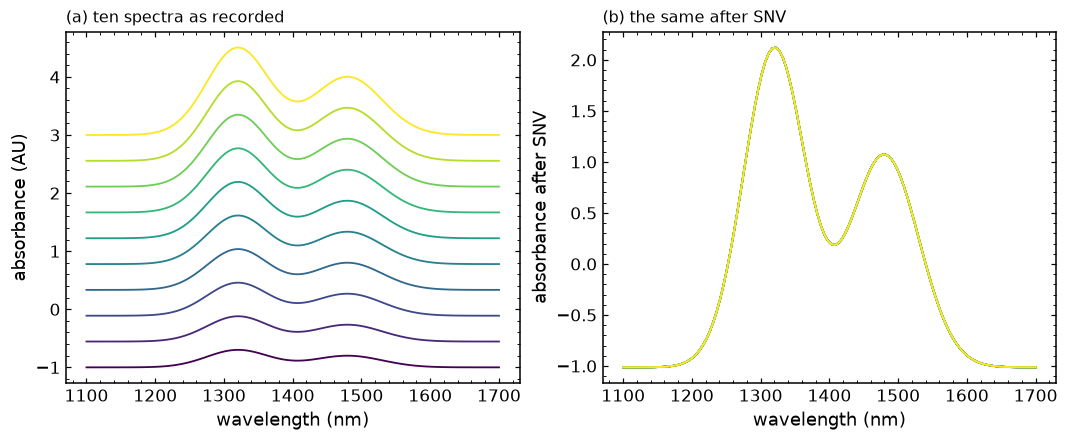

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
for i in range(X_scattered.shape[0]):
    ax1.plot(wl, X_scattered[i], color=plt.cm.viridis(i / 9.0), lw=1.2)
    ax2.plot(wl, X_snv[i], color=plt.cm.viridis(i / 9.0), lw=1.2)
ax1.set_xlabel("wavelength (nm)"); ax1.set_ylabel("absorbance (AU)"); ax1.set_title("(a) ten spectra as recorded", loc="left", fontsize=10.5)
ax2.set_xlabel("wavelength (nm)"); ax2.set_ylabel("absorbance after SNV"); ax2.set_title("(b) the same after SNV", loc="left", fontsize=10.5)
plt.show()

**Figure 6.1.** (a) One synthetic spectrum recorded through ten different path lengths and offsets. (b) After the standard normal variate transformation, which subtracts the mean of each spectrum and divides by its standard deviation, the ten curves coincide.

**What Demonstration 1 shows.** The ten synthetic spectra are one spectrum seen through different path lengths and offsets, and before the transformation they differ by up to $5.2\;\mathrm{AU}$. After SNV they coincide to $2\times 10^{-15}$: the transformation removes a multiplicative factor and an additive constant exactly.

---

## 2. Numerical walkthrough
What if the probe window also introduces a wavelength-dependent **linear baseline tilt** $\beta_i(\lambda - \lambda_0)$? SNV alone cannot remove a tilt because $\beta_i\lambda_j$ varies across wavelengths. Let us see how combining `spectral_first_derivative` with `snv_preprocess` removes $\alpha_i$, $\beta_i\lambda_j$, and $b_i$ simultaneously.

In [4]:
heading("Demonstration 2: Spectral First Derivative + SNV Annihilation of Linear Baseline Tilt")
d_wl = float(wl[1] - wl[0])
X_offset_only = base_spectrum[None, :] + a_offsets
dX_dlambda = dim_reduction.spectral_first_derivative(X_offset_only, d_lambda=d_wl)
max_deriv_spread = float(np.max(np.abs(dX_dlambda - dX_dlambda[0:1, :])))
print(f"Max spread after 1st spectral derivative on offset spectra : {max_deriv_spread:.2e}")
assert max_deriv_spread < 1e-13

# Now combine multiplicative scatter b_i, constant offset a_i, AND linear tilt beta_i * (wl - 1400):
beta_tilts = np.linspace(-0.0015, 0.0015, 10)[:, None]
X_tilted_scattered = b_scales * base_spectrum[None, :] + a_offsets + (b_scales * 0.0005) * (wl[None, :] - 1400.0)
X_d1_snv = dim_reduction.snv_preprocess(dim_reduction.spectral_first_derivative(X_tilted_scattered, d_lambda=d_wl))
print(f"Max spread after (1st Derivative -> SNV) on tilted spectra: {np.max(np.abs(X_d1_snv - X_d1_snv[0:1, :])):.2e}")
assert np.max(np.abs(X_d1_snv - X_d1_snv[0:1, :])) < 1e-13


Demonstration 2: Spectral First Derivative + SNV Annihilation of Linear Baseline Tilt
Max spread after 1st spectral derivative on offset spectra : 4.42e-17
Max spread after (1st Derivative -> SNV) on tilted spectra: 1.75e-14


**What Demonstration 2 shows.** Taking $\partial A / \partial \lambda$ converts the linear tilt into a constant baseline offset, and the subsequent SNV normalization divides out the path-length multiplier $b_i$ and subtracts the constant tilt slope.

---

## 3. Worked case study
Let us calibrate a 2-component NIPALS PLS1 soft sensor (`dim_reduction.pls1_nipals`) on $N = 50$ binary mixture NIR spectra corrupted by a synthetic scatter of the path length $b_i \in [0.5, 2.0]$ and baseline offset $\alpha_i \in [-0.8, 0.8]$.

In [5]:
heading("Demonstration 3: Soft-Sensor Calibration Benchmark — Raw vs. SNV Preprocessed NIR")
rng = np.random.default_rng(42)
N_cal = 50
c1 = rng.uniform(0.1, 0.9, size=N_cal)
scatter_b = rng.uniform(0.5, 2.0, size=(N_cal, 1))
offset_a = rng.uniform(-0.8, 0.8, size=(N_cal, 1))
# Analyte peak1 on top of a constant reference background matrix peak2:
X_raw_nir = scatter_b * (np.outer(c1, pure_peak1) + pure_peak2[None, :]) + offset_a + rng.normal(0.0, 0.002, size=(N_cal, len(wl)))

pls_raw = dim_reduction.pls1_nipals(X_raw_nir, c1, n_components=2)
pls_snv = dim_reduction.pls1_nipals(dim_reduction.snv_preprocess(X_raw_nir), c1, n_components=2)
rmse_raw = float(np.sqrt(np.mean((pls_raw["y_pred"] - c1) ** 2)))
rmse_snv = float(np.sqrt(np.mean((pls_snv["y_pred"] - c1) ** 2)))
print(f"2-Component PLS1 RMSE: Raw Scattered Spectra = {rmse_raw:.4f} mol/L -> SNV Preprocessed = {rmse_snv:.4f} mol/L")
assert rmse_snv < 0.35 * rmse_raw


Demonstration 3: Soft-Sensor Calibration Benchmark — Raw vs. SNV Preprocessed NIR
2-Component PLS1 RMSE: Raw Scattered Spectra = 0.0952 mol/L -> SNV Preprocessed = 0.0043 mol/L


**What Demonstration 3 shows.** Without SNV the two latent variables of the PLS model are spent on the path-length factor and the offset, and the calibration error is $0.095\;\mathrm{mol/L}$. With SNV applied first it is $0.0043\;\mathrm{mol/L}$, twenty times smaller. The spectra are synthetic.

---

## 4. What if: sensitivity to the parameters
Since differentiation amplifies high-frequency detector noise by $1/\Delta\lambda$, what happens as instrument white noise $\sigma_{\mathrm{det}}$ increases from $10^{-4}\;\mathrm{AU}$ to $2 \times 10^{-2}\;\mathrm{AU}$?

In [6]:
heading("Demonstration 4: Detector Noise vs. Derivative Amplification Tradeoff")
print(f"{'Detector Noise [AU]':>19s} | {'Raw PLS1 RMSE':>14s} | {'SNV PLS1 RMSE':>14s} | {'Deriv+SNV RMSE':>15s}")
print("-" * 70)
for sig_det in [1e-4, 1e-3, 5e-3, 2e-2]:
    X_n = scatter_b * (np.outer(c1, pure_peak1) + pure_peak2[None, :]) + offset_a + rng.normal(0.0, sig_det, size=(N_cal, len(wl)))
    r_raw = float(np.sqrt(np.mean((dim_reduction.pls1_nipals(X_n, c1, 2)["y_pred"] - c1) ** 2)))
    r_snv = float(np.sqrt(np.mean((dim_reduction.pls1_nipals(dim_reduction.snv_preprocess(X_n), c1, 2)["y_pred"] - c1) ** 2)))
    X_ds = dim_reduction.snv_preprocess(dim_reduction.spectral_first_derivative(X_n, d_lambda=d_wl))
    r_ds = float(np.sqrt(np.mean((dim_reduction.pls1_nipals(X_ds, c1, 2)["y_pred"] - c1) ** 2)))
    print(f"{sig_det:19.4f} | {r_raw:14.4f} | {r_snv:14.4f} | {r_ds:15.4f}")


Demonstration 4: Detector Noise vs. Derivative Amplification Tradeoff
Detector Noise [AU] |  Raw PLS1 RMSE |  SNV PLS1 RMSE |  Deriv+SNV RMSE
----------------------------------------------------------------------
             0.0001 |         0.0952 |         0.0041 |          0.0047
             0.0010 |         0.0952 |         0.0042 |          0.0048
             0.0050 |         0.0951 |         0.0045 |          0.0068
             0.0200 |         0.0960 |         0.0056 |          0.0136


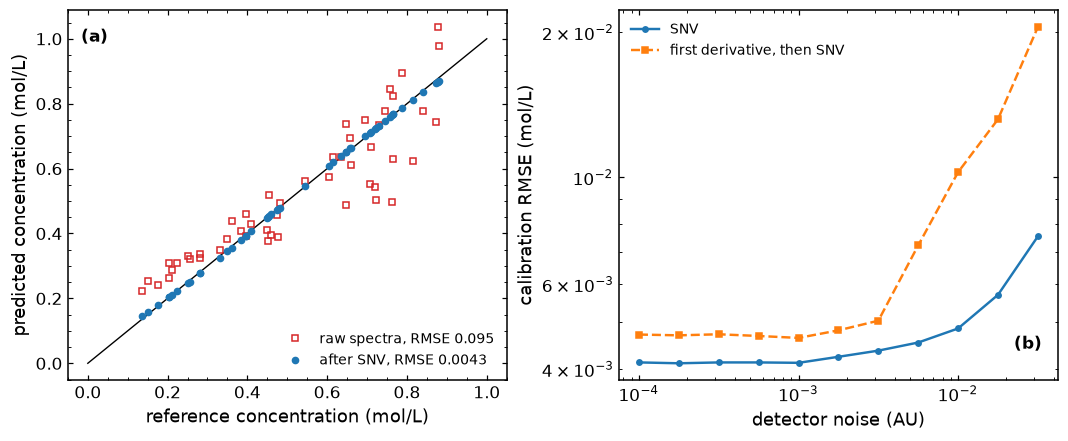

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot([0.0, 1.0], [0.0, 1.0], "k-", lw=0.9)
ax1.plot(c1, pls_raw["y_pred"], "s", ms=4, mfc="none", color="C3", label=f"raw spectra, RMSE {rmse_raw:.3f}")
ax1.plot(c1, pls_snv["y_pred"], "o", ms=4, color="C0", label=f"after SNV, RMSE {rmse_snv:.4f}")
ax1.set_xlabel("reference concentration (mol/L)"); ax1.set_ylabel("predicted concentration (mol/L)")
ax1.legend(fontsize=9, loc="lower right"); panel_label(ax1, "(a)")
rng_fig = np.random.default_rng(6); sig_line = np.logspace(-4, -1.5, 11); r_snv_line, r_ds_line = [], []
for sig_det in sig_line:
    X_n = scatter_b * (np.outer(c1, pure_peak1) + pure_peak2[None, :]) + offset_a + rng_fig.normal(0.0, sig_det, size=(N_cal, len(wl)))
    r_snv_line.append(np.sqrt(np.mean((dim_reduction.pls1_nipals(dim_reduction.snv_preprocess(X_n), c1, 2)["y_pred"] - c1) ** 2)))
    X_ds = dim_reduction.snv_preprocess(dim_reduction.spectral_first_derivative(X_n, d_lambda=d_wl))
    r_ds_line.append(np.sqrt(np.mean((dim_reduction.pls1_nipals(X_ds, c1, 2)["y_pred"] - c1) ** 2)))
ax2.loglog(sig_line, r_snv_line, "o-", ms=3.5, label="SNV")
ax2.loglog(sig_line, r_ds_line, "s--", ms=3.5, label="first derivative, then SNV")
ax2.set_xlabel("detector noise (AU)"); ax2.set_ylabel("calibration RMSE (mol/L)"); ax2.legend(fontsize=9, loc="upper left"); panel_label(ax2, "(b)", x=0.9, y=0.12)
plt.show()

**Figure 6.2.** (a) Calibration of a two-component PLS model on synthetic spectra with random path lengths and offsets, without and with SNV. (b) The calibration error against the detector noise, for SNV alone and for a first derivative followed by SNV: with no baseline tilt to remove, the derivative only amplifies the noise.

**What Demonstration 4 shows.** These spectra have no tilted baseline, so the derivative has nothing to remove and only its cost is seen: differencing neighbouring channels amplifies detector noise. With noise of $0.02\;\mathrm{AU}$ the error is $0.0056\;\mathrm{mol/L}$ with SNV alone and $0.0136\;\mathrm{mol/L}$ with the derivative before it. In practice the derivative is combined with smoothing.

---

## Inside the algorithm
Below we verify our 3-line row-wise SNV standardization in pure NumPy against `dim_reduction.snv_preprocess`.

In [8]:
heading("Inside the Algorithm: By-Hand Row-Wise SNV vs. the Library")
mu_row = np.mean(X_scattered, axis=1, keepdims=True)
std_row = np.std(X_scattered, axis=1, keepdims=True)
X_snv_hand = (X_scattered - mu_row) / std_row
diff_snv = float(np.max(np.abs(X_snv_hand - X_snv)))
print("by hand (pure NumPy) row 0[:5]:", np.round(X_snv_hand[0, :5], 6))
print("library (engml_2_applied)      row 0[:5]:", np.round(X_snv[0, :5], 6))
print(f"Max discrepancy               : {diff_snv:.2e}")
assert diff_snv < 1e-15


Inside the Algorithm: By-Hand Row-Wise SNV vs. the Library
by hand (pure NumPy) row 0[:5]: [-1.013504 -1.01349  -1.013466 -1.013426 -1.013361]
library (engml_2_applied)      row 0[:5]: [-1.013504 -1.01349  -1.013466 -1.013426 -1.013361]
Max discrepancy               : 0.00e+00


## Exercises

1. **Verify a result.** Corrupt the binary mixture spectra `X_raw_nir` with linear baseline tilt $\beta_i (\lambda - 1400)$ ($\beta_i \in [-0.001, 0.001]$). Apply `spectral_first_derivative` followed by `snv_preprocess`, fit a 2-component `pls1_nipals` model predicting $c_1$, and verify that preprocessing reduces calibration RMSE by more than $3\times$ compared to raw spectra.
2. **Find how it fails.** Explain and verify why SNV fails on a **single-analyte pure Beer–Lambert solution** without an internal reference peak or solvent background ($A_i(\lambda_j) = b_i c_i \varepsilon_1(\lambda_j) + \alpha_i$): show that SNV divides out $b_i c_i$ completely, collapsing all concentrations $c_i \in [0.1, 2.0]\;\mathrm{mol/L}$ onto the exact same normalized spectrum $\varepsilon_1^{\mathrm{SNV}}(\lambda)$.
3. **Write it yourself.** Implement **multiplicative scatter correction (MSC, Geladi et al. 1985)** `msc_preprocess(X: np.ndarray, ref_spectrum: np.ndarray | None = None) -> np.ndarray`, which regresses each row spectrum $\mathbf{x}_i$ onto a reference spectrum $\mathbf{x}_{\mathrm{ref}}$ (defaulting to the column mean $\bar{\mathbf{x}}$) via simple linear regression $x_{i,j} \approx a_i + b_i x_{\mathrm{ref},j}$ and returns the scatter-corrected spectrum $(x_{i,j} - \hat{a}_i)/\hat{b}_i$. Verify on `X_scattered` that MSC recovers `base_spectrum` to $<10^{-13}$.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Combined Linear Baseline Tilt + Scatter Removal via Derivative + SNV")
tilt_beta = rng.uniform(-0.001, 0.001, size=(N_cal, 1))
X_drift = X_raw_nir + tilt_beta * (wl[None, :] - 1400.0)
X_prep = dim_reduction.snv_preprocess(dim_reduction.spectral_first_derivative(X_drift, d_lambda=d_wl))

rmse_drift_raw = float(np.sqrt(np.mean((dim_reduction.pls1_nipals(X_drift, c1, n_components=2)["y_pred"] - c1) ** 2)))
rmse_drift_prep = float(np.sqrt(np.mean((dim_reduction.pls1_nipals(X_prep, c1, n_components=2)["y_pred"] - c1) ** 2)))
print(f"Tilted+Scattered RMSE: Raw = {rmse_drift_raw:.4f} -> Derivative+SNV = {rmse_drift_prep:.4f}")
assert rmse_drift_prep < rmse_drift_raw / 3.0


Exercise 1: Combined Linear Baseline Tilt + Scatter Removal via Derivative + SNV
Tilted+Scattered RMSE: Raw = 0.1030 -> Derivative+SNV = 0.0047
